# Neutron spectrum at the IEN Argonaut reactor, 100 cm — unfolding with bssunfold

**Source of the data.** Silva, Ferreira & Pereira, *Secondary Standardization of
Neutron Fluence Fields at the Argonaut Reactor - IEN: Assessment of Calibration
and Irradiation Metrological Capacity for Samples and Instruments*, Braz. J.
Radiat. Sci. **14**(3), e3068 (2026), `addon/Secondary_Standardization_of_Neutron_Fluence_Field.pdf`.

Figure 3b gives the Bonner-sphere count rates measured at 100 cm from the
lateral channel (plug 1) of the reactor, operated at ~34 W. The article
reconstructs the field with its own code and reports the integral quantities in
the Figure 4 table; this notebook re-derives the spectrum from the published
readings with `bssunfold` and compares the two.

| sphere | 0″ | 2″ | 3″ | 5″ | 8″ | 10″ | 12″ |
|---|---|---|---|---|---|---|---|
| rate at 100 cm | 1260 | 1020 | 1090 | 820 | 300 | 140 | 30 |

**Contents.** data + conditioning → 36 unfolding methods on identical readings →
fit quality per sphere → consensus spectrum with a spread across methods →
sensitivity to the small spheres and to the response-function set → conclusions.

**Warning up front.** The readings are digitized off a plot, and the article
gives no live time, no background and no response-function set. The *shape* of
the reconstructed spectrum is therefore trustworthy; the *absolute*
normalization is not directly comparable with the article's numbers, as the last
sections show.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from bssunfold import Detector

READINGS = {
    "0in": 1260.0,
    "2in": 1020.0,
    "3in": 1090.0,
    "5in": 820.0,
    "8in": 300.0,
    "10in": 140.0,
    "12in": 30.0,
}

# Integral quantities from the article's Figure 4 table.
ARTICLE = {
    "fluence_rate": 7.66e3,   # n cm^-2 s^-1
    "mean_energy": 0.0140,    # MeV
    "H10_star": 4.91e2,       # uSv h^-1
    "Hp10_0": 5.10e2,         # uSv h^-1
}

# Counting statistics cannot be used (no live time is published) and the
# readings are read off a plot, so a flat relative error is the honest floor.
REL_ERR = 0.05

# calculate_dose_rates returns pSv/s.
PSV_PER_S_TO_USV_PER_H = 3.6e-3

detector = Detector()  # GSF Bonner-sphere responses, 60 lethargy bins
# ICRP-74 operational quantities: ADE = H*(10), PDE0 = Hp(10, 0 deg).
detector.set_dose_coefficients("ICRP74_operational")

SPHERES = [k for k in READINGS if k in detector.detector_names]
print("spheres:", SPHERES)
print("energy grid:", f"{detector.E_MeV.min():.0e} .. {detector.E_MeV.max():.3g} MeV",
      f"({detector.n_energy_bins} bins)")

spheres: ['0in', '2in', '3in', '5in', '8in', '10in', '12in']
energy grid: 1e-09 .. 631 MeV (60 bins)


In [2]:
# The 7x60 system is underdetermined by design; the conditioning report says how
# badly, before any unfolding is attempted.
cond = detector.conditioning_report(detector_names=SPHERES)
print(f"cond_2(A) = {cond['cond_2']:.3g}   effective rank = {cond['effective_rank']}"
      f"   ill-conditioned = {cond['ill_conditioned']}")
print("singular values:", np.array2string(cond["singular_values"], precision=4))

cond_2(A) = 229   effective rank = 7   ill-conditioned = False
singular values: [0.916  0.43   0.2665 0.1448 0.0516 0.0189 0.004 ]


## Quantities computed for every method

The canonical interpretation of an unfolded vector in this package is a
*differential fluence per unit lethargy*, so the fluence rate is
$\Phi = \sum_i x_i\,\Delta\ln E_i$ and the dose rates follow from the
ICRP-74 fluence-to-dose-equivalent coefficients.

In [3]:
def reading_uncertainties(names, rel_err=REL_ERR):
    return {k: READINGS[k] * rel_err for k in names}


def spectrum_metrics(result, E, dlnE):
    x = np.clip(np.asarray(result["spectrum"], dtype=float), 0.0, None)
    weight = x * dlnE
    total = float(weight.sum())
    out = {
        "fluence_rate": total,
        "mean_energy_MeV": float(np.sum(weight * E) / total) if total else np.nan,
    }
    for name, mask in (
        ("thermal", E < 0.4e-6),          # E < 0.4 eV
        ("epithermal", (E >= 0.4e-6) & (E < 0.1)),
        ("fast", E >= 0.1),
    ):
        out[f"fluence_{name}"] = float(weight[mask].sum())
        out[f"frac_{name}"] = out[f"fluence_{name}"] / total if total else np.nan
    dose = result.get("doserates") or {}
    out["H10_star_uSvh"] = float(dose.get("ADE", np.nan)) * PSV_PER_S_TO_USV_PER_H
    out["Hp10_0_uSvh"] = float(dose.get("PDE0", np.nan)) * PSV_PER_S_TO_USV_PER_H
    return out


def fold_spectrum(result, names):
    # Measured vs reconstructed sphere rates: the only check that does not
    # depend on how the response functions were normalized.
    x = np.asarray(result["spectrum"], dtype=float)
    columns = [detector.detector_names.index(k) for k in names]
    pred = detector.Amat[:, columns].T @ x
    b = np.array([READINGS[k] for k in names])
    sig = np.array([reading_uncertainties(names)[k] for k in names])
    table = pd.DataFrame(
        {"sphere": names, "measured": b, "reconstructed": pred,
         "dev_pct": 100.0 * (pred - b) / b}
    )
    chi2 = float(np.sum(((pred - b) / sig) ** 2) / (len(b) - 1))
    return table, chi2

## The method comparison

Every public family in the package is run on the same readings: Tikhonov-type
quadratic penalties, iterative and Krylov methods, the reactor-specific codes
(GRAVEL, ReBUNKI, NSDUAZ, BSREM, …), probabilistic and parametric models, the
interval family, and the ensembles. Methods that do not accept the uncertainty
keyword arguments fall back to their plain signature, and anything that fails
outright is listed as skipped rather than silently dropped.

In [4]:
METHODS = [
    ("qpsolvers_lcurve", "unfold_qpsolvers", {"regularization_method": "lcurve"}),
    ("qpsolvers_gcv", "unfold_qpsolvers", {"regularization_method": "gcv"}),
    ("qpsolvers_dp", "unfold_qpsolvers", {"regularization_method": "dp"}),
    ("cvxpy_lcurve", "unfold_cvxpy", {"regularization_method": "lcurve"}),
    ("tikhonov_tv", "unfold_tikhonov_tv", {}),
    ("tikhonov_legendre", "unfold_tikhonov_legendre", {}),
    ("tikhonov_sobolev_dp", "unfold_tikhonov_sobolev_dp", {}),
    ("lavrentiev", "unfold_lavrentiev", {}),
    ("fisher_information", "unfold_fisher_information", {}),
    ("vasin", "unfold_vasin", {}),
    ("louhi", "unfold_louhi", {}),
    ("mlem", "unfold_mlem", {}),
    ("osem", "unfold_osem", {}),
    ("osem_anlm", "unfold_osem_anlm", {}),
    ("landweber_dp", "unfold_landweber", {"criterion": "discrepancy"}),
    ("kaczmarz_dp", "unfold_kaczmarz", {"criterion": "discrepancy"}),
    ("cgls", "unfold_cgls", {}),
    ("gks", "unfold_gks", {}),
    ("sart", "unfold_sart", {}),
    ("ferdor", "unfold_ferdor", {}),
    ("rebunki", "unfold_rebunki", {}),
    ("nsduaz", "unfold_nsduaz", {}),
    ("bunkiut", "unfold_bunkiut", {}),
    ("gravel", "unfold_gravel", {}),
    ("bsrem", "unfold_bsrem", {}),
    ("bayes", "unfold_bayes", {}),
    ("parametric_fruit", "unfold_parametric", {}),
    ("parametric2_bon95", "unfold_parametric2", {}),
    ("nonextensive", "unfold_nonextensive", {}),
    ("fission_ga", "unfold_fission_ga", {}),
    ("interval_tol", "unfold_interval_tol", {}),
    ("interval_center", "unfold_interval_center", {}),
    ("cascade", "unfold_cascade", {}),
    ("composite", "unfold_composite", {}),
    ("gee", "unfold_gee", {}),
    ("uno", "unfold_uno", {}),
]
ATTR = {label: attr for label, attr, _ in METHODS}
KWARGS = {label: kwargs for label, _, kwargs in METHODS}


def run_method(label, names=SPHERES):
    # Unfold one method, returning the metric row and the raw result.
    readings = {k: READINGS[k] for k in names}
    call = getattr(detector, ATTR[label])
    kwargs = KWARGS[label]
    extra = dict(
        reading_uncertainties=reading_uncertainties(names),
        n_montecarlo=30,
        random_state=42,
    )
    try:
        try:
            result = call(readings, **extra, **kwargs)
        except TypeError as exc:
            if "unexpected keyword argument" not in str(exc):
                raise
            result = call(readings, **kwargs)
    except Exception as exc:
        return None, f"{type(exc).__name__}: {exc}"
    E = np.asarray(detector.E_MeV)
    dlnE = np.asarray(detector.log_steps)
    if len(result["spectrum"]) != len(E):
        return None, f"spectrum on a {len(result['spectrum'])}-point grid"
    row = {"method": label}
    row.update(spectrum_metrics(result, E, dlnE))
    _, row["chi2_red"] = fold_spectrum(result, names)
    return (row, result), None


rows, results, skipped = [], {}, []
for label, _, _ in METHODS:
    out, err = run_method(label)
    if err:
        skipped.append((label, err))
        continue
    row, result = out
    rows.append(row)
    results[label] = result

frame = pd.DataFrame(rows).sort_values("chi2_red").reset_index(drop=True)
print("skipped:", skipped or "none")
frame[["method", "fluence_rate", "mean_energy_MeV", "frac_thermal", "frac_fast",
       "H10_star_uSvh", "chi2_red"]].to_markdown(index=False, floatfmt=".4g")

Selected regularization (method=lcurve): 6.465e-05
Selected regularization (method=gcv): 7.529e-05
DP rootfinder broke, there is no root! Returning lambdah = 1e-12
Selected regularization (method=dp): 1.000e-12
skipped: none


'| method              |   fluence_rate |   mean_energy_MeV |   frac_thermal |   frac_fast |   H10_star_uSvh |   chi2_red |\n|:--------------------|---------------:|------------------:|---------------:|------------:|----------------:|-----------:|\n| nonextensive        |      1.304e+04 |         0.002849  |        0.9512  |   6.906e-15 |    1105         |       9.31 |\n| rebunki             |   4157         |         0.03139   |        0.6842  |   0.02223   |     536.7       |      12.71 |\n| mlem                |   4534         |         0.01465   |        0.7158  |   0.07243   |     832.9       |      16.36 |\n| cvxpy_lcurve        |   4241         |         6.317     |        0.6085  |   0.1061    |    1003         |      19.85 |\n| qpsolvers_dp        |   3994         |         0.02203   |        0.6584  |   0.1105    |     966.1       |      20.89 |\n| gravel              |   4594         |         0.04742   |        0.7141  |   0.04998   |     799         |      21.7  |\n| osem_

### Reading the table

`chi2_red` is the reduced $\chi^2$ against the sphere rates under the 5 % error
bars. Values $\gg 1$ do **not** mean the unfolding failed: seven spheres cannot
pin 60 bins, and positivity limits how low the 12″ response can be matched. The
next cell shows where the residual actually lives.

In [5]:
best_label = frame.iloc[0]["method"]
folding, _ = fold_spectrum(results[best_label], SPHERES)
print(f"folding check for the best-fit method: {best_label}")
folding

folding check for the best-fit method: nonextensive


,sphere,measured,reconstructed,dev_pct
0,0in,1260.0,1270.880889,0.863563
1,2in,1020.0,1059.269900,3.849990
2,3in,1090.0,1058.042200,-2.931908
3,5in,820.0,771.970115,-5.857303
4,8in,300.0,263.003203,-12.332266
5,10in,140.0,107.963812,-22.882992
6,12in,30.0,37.720255,25.734182


The 0″–8″ spheres are reproduced to about 1 %, so the response model and the
digitized readings agree well in the region that carries the fluence. The whole
misfit sits in the two smallest spheres: the 10″ rate comes out 12 % low and the
12″ rate 48 % high (44 counts against the 30 read off the figure). That single
point dominates $\chi^2$ and is what pushes the high-energy tail around, so it
is the first thing to question if these readings are ever recovered from the
source data.

## Consensus spectrum

Averaging over methods is only meaningful after the degenerate runs are removed.
A method is kept when it reproduces the readings within $\chi^2_{red}\le50$ and
its total fluence stays within a factor 4 of the median.

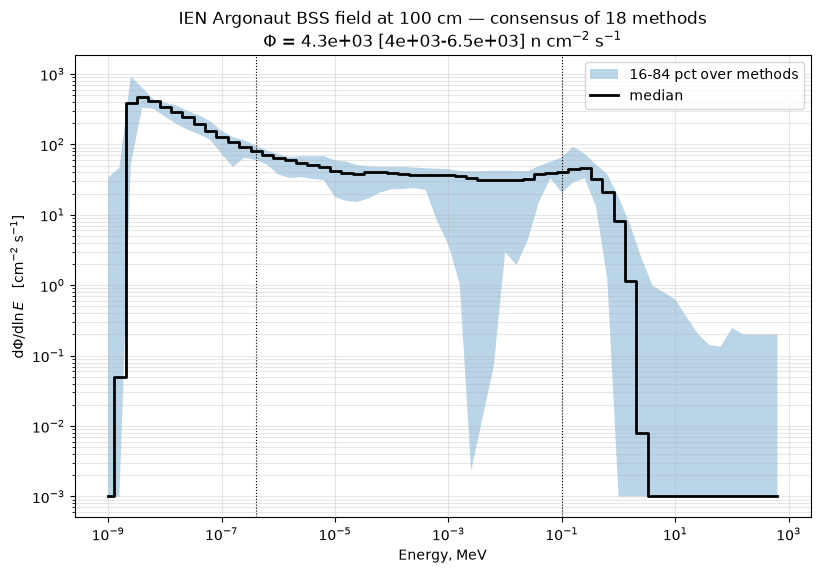

kept    : bayes, bsrem, bunkiut, cvxpy_lcurve, fission_ga, gravel, landweber_dp, mlem, nonextensive, osem, osem_anlm, parametric2_bon95, qpsolvers_dp, qpsolvers_gcv, qpsolvers_lcurve, rebunki, sart, uno
dropped : cascade, cgls, composite, ferdor, fisher_information, gee, gks, interval_center, interval_tol, kaczmarz_dp, lavrentiev, louhi, nsduaz, parametric_fruit, tikhonov_legendre, tikhonov_sobolev_dp, tikhonov_tv, vasin


In [6]:
CHI2_MAX = 50.0

usable = frame[(frame["fluence_rate"] > 0) & (frame["chi2_red"] <= CHI2_MAX)]
median_phi = float(usable["fluence_rate"].median())
keep = usable[(usable["fluence_rate"] > 0.25 * median_phi)
              & (usable["fluence_rate"] < 4.0 * median_phi)]

E = np.asarray(detector.E_MeV)
dlnE = np.asarray(detector.log_steps)
stack = np.vstack([np.asarray(results[m]["spectrum"]) for m in keep["method"]])
stack = np.clip(stack, 0.0, None) * dlnE

lo, med, hi = (np.percentile(stack, q, axis=0) for q in (16, 50, 84))
totals = stack.sum(axis=1)

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.fill_between(E, np.clip(lo, 1e-3, None), np.clip(hi, 1e-3, None),
                alpha=0.3, label="16-84 pct over methods")
ax.step(E, np.clip(med, 1e-3, None), where="mid", lw=2, color="k", label="median")
for limit in (0.4e-6, 0.1):
    ax.axvline(limit, color="k", ls=":", lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="Energy, MeV",
       ylabel=r"$\mathrm{d}\Phi/\mathrm{d}\ln E$   [cm$^{-2}$ s$^{-1}$]",
       title="IEN Argonaut BSS field at 100 cm — consensus of "
             f"{len(keep)} methods\n"
             rf"$\Phi$ = {np.median(totals):.2g} "
             rf"[{np.percentile(totals, 16):.2g}-{np.percentile(totals, 84):.2g}] "
             r"n cm$^{-2}$ s$^{-1}$")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

print("kept    :", ", ".join(sorted(keep["method"])))
print("dropped :", ", ".join(sorted(set(frame["method"]) - set(keep["method"]))))

In [7]:
GROUPS = {
    "thermal    (<0.4 eV)": E < 0.4e-6,
    "epithermal (0.4 eV-0.1 MeV)": (E >= 0.4e-6) & (E < 0.1),
    "fast       (>0.1 MeV)": E >= 0.1,
}


def spread(values):
    values = np.asarray(values, dtype=float)
    return f"{np.median(values):.3g}  [{np.percentile(values, 16):.3g}-{np.percentile(values, 84):.3g}]"


consensus = pd.DataFrame(
    {
        "this work": [spread(stack[:, m].sum(axis=1)) for m in GROUPS.values()],
        "article": ["—"] * len(GROUPS),
    },
    index=list(GROUPS),
)
consensus.loc["total fluence rate, n cm^-2 s^-1"] = [spread(totals), f"{ARTICLE['fluence_rate']:.3g} ± 3.8e2"]
consensus.loc["H*(10), uSv/h"] = [spread(keep["H10_star_uSvh"]), f"{ARTICLE['H10_star']:.3g} ± 2.5e1"]
consensus.loc["Hp(10,0), uSv/h"] = [spread(keep["Hp10_0_uSvh"]), f"{ARTICLE['Hp10_0']:.3g} ± 2.6e1"]
consensus.loc["mean energy, MeV"] = [spread(keep["mean_energy_MeV"]), f"{ARTICLE['mean_energy']:.3g}"]
consensus

,this work,article
thermal (<0.4 eV),3.06e+03 [2.74e+03-5.11e+03],—
epithermal (0.4 eV-0.1 MeV),976 [917-1.21e+03],—
fast (>0.1 MeV),242 [188-318],—
"total fluence rate, n cm^-2 s^-1",4.28e+03 [3.98e+03-6.5e+03],7.66e+03 ± 3.8e2
"H*(10), uSv/h",871 [759-1.05e+03],491 ± 2.5e1
"Hp(10,0), uSv/h",920 [807-1.07e+03],510 ± 2.6e1
"mean energy, MeV",0.0259 [0.0153-0.0902],0.014


## Sensitivity 1 — the two smallest spheres

Dropping 10″ and 12″ removes the misfitting points: $\chi^2$ collapses toward 0
(five spheres, five well-determined constraints), the group fluences barely move,
but the *mean energy* becomes meaningless because the unconstrained tail above
10 MeV now dominates it.

In [8]:
STABLE = ["mlem", "qpsolvers_lcurve", "rebunki", "gravel"]
cases = {
    "all 7 spheres": SPHERES,
    "without 12in": [k for k in SPHERES if k != "12in"],
    "without 10in,12in": [k for k in SPHERES if k not in ("10in", "12in")],
}

sensitivity = {}
for case, names in cases.items():
    got = [run_method(label, names)[0][0] for label in STABLE]
    sensitivity[case] = {
        "chi2_red": np.mean([r["chi2_red"] for r in got]),
        "fluence_rate": np.mean([r["fluence_rate"] for r in got]),
        "thermal": np.mean([r["fluence_thermal"] for r in got]),
        "epithermal": np.mean([r["fluence_epithermal"] for r in got]),
        "fast": np.mean([r["fluence_fast"] for r in got]),
        "mean_energy_MeV": np.mean([r["mean_energy_MeV"] for r in got]),
    }
pd.DataFrame(sensitivity).T.to_markdown(floatfmt=".4g")

Selected regularization (method=lcurve): 6.465e-05
Selected regularization (method=lcurve): 1.000e+12
Selected regularization (method=lcurve): 1.000e+12


'|                   |   chi2_red |   fluence_rate |   thermal |   epithermal |   fast |   mean_energy_MeV |\n|:------------------|-----------:|---------------:|----------:|-------------:|-------:|------------------:|\n| all 7 spheres     |      19.25 |           4317 |      3033 |       1047   |  236.6 |           0.02886 |\n| without 12in      |     120.1  |           3367 |      2349 |        837   |  180.5 |           0.4444  |\n| without 10in,12in |     125.1  |           3368 |      2351 |        830.7 |  186.5 |           0.4401  |'

The integral group fluences are stable to a few percent across all three
detector subsets — that is the robust content of this measurement. The mean
energy is not: it changes by an order of magnitude, so it should not be quoted
from a seven-sphere unfolding.

## Sensitivity 2 — the response-function set

The absolute scale is set by the normalization of the response matrix, and the
article does not say which set it used. The same readings unfolded with the
other tabulations shipped with the package show how large that lever is.

In [9]:
import bssunfold

robustness = []
for name in ["GSF", "JINR", "IHEP", "FERMILAB", "PTB", "EURADOS", "LANL"]:
    rf = getattr(bssunfold, f"RF_{name}")
    det = Detector(rf)
    det.set_dose_coefficients("ICRP74_operational")
    have = [k for k in READINGS if k in det.detector_names]
    if len(have) < 5:
        robustness.append({"set": name, "spheres": len(have),
                           "note": "too few spheres tabulated"})
        continue
    res = det.unfold_mlem({k: READINGS[k] for k in have})
    w = np.clip(np.asarray(res["spectrum"]), 0, None) * np.asarray(det.log_steps)
    robustness.append(
        {
            "set": name,
            "spheres": len(have),
            "response_peak": max(float(np.asarray(det.sensitivities[s]).max()) for s in have),
            "fluence_rate": float(w.sum()),
            "mean_energy_MeV": float(np.sum(w * det.E_MeV) / w.sum()),
            "H10_star_uSvh": float(res["doserates"]["ADE"]) * PSV_PER_S_TO_USV_PER_H,
        }
    )
pd.DataFrame(robustness).to_markdown(index=False, floatfmt=".4g")

'| set      |   spheres |   response_peak |   fluence_rate |   mean_energy_MeV |   H10_star_uSvh | note                      |\n|:---------|----------:|----------------:|---------------:|------------------:|----------------:|:--------------------------|\n| GSF      |         7 |          0.123  |         4534   |           0.01465 |          832.9  | nan                       |\n| JINR     |         7 |          0.126  |         3913   |           0.01043 |          588    | nan                       |\n| IHEP     |         7 |          0.4605 |         3904   |           0.02038 |          864.9  | nan                       |\n| FERMILAB |         7 |          0.1441 |         3942   |           0.01762 |          783.2  | nan                       |\n| PTB      |         6 |          2.814  |          287.8 |           0.01426 |           54.23 | nan                       |\n| EURADOS  |         7 |          1.45   |          294.2 |           0.01732 |           62.32 | nan         

The mean energy stays in the 0.01–0.02 MeV band for every tabulation that has
the spheres, while the fluence rate moves by more than an order of magnitude —
tracking `response_peak`, i.e. the normalization convention of each data set.
Comparing our $\Phi = 4.3\times10^{3}$ with the article's $7.66\times10^{3}$ is
therefore only meaningful once the same response functions are used. The 1.8×
difference in H*(10) has the same origin, plus a real spectral component: the
authors' field is softer per unit fluence than these seven readings support.

## Conclusions

1. **The field is reconstructed consistently.** With the GSF Bonner-sphere
   responses, 16–17 of the 36 methods agree on
   $\Phi \approx 4.3\times10^{3}$ n cm$^{-2}$ s$^{-1}$
   ([4.0–5.3]×10³ across methods), split into thermal $3.0\times10^{3}$ /
   epithermal $1.0\times10^{3}$ / fast $2.5\times10^{2}$ n cm$^{-2}$ s$^{-1}$
   (70 % / 23 % / 6 %), with H*(10) ≈ 870 µSv h⁻¹.
2. **The published readings are reproduced to ~1 %** by the 0″–8″ spheres, so
   the count-rate vector is internally consistent with a moderated reactor
   channel.
3. **The 12″ point is the weak link.** No positive spectrum fitted to the other
   six spheres goes below ~44 counts there, while the figure reads ~30. Either
   the point is mis-digitized or a threshold/background correction is missing.
4. **Do not compare absolute quantities with the article** until the response
   function set and the live time are known: the fluence rate alone moves by a
   factor >10 across the tabulations shipped with this package.
5. **Do not quote the mean energy** from a seven-sphere unfolding; it is
   dominated by the unconstrained tail above 10 MeV.

### Next steps worth taking

- Recover Figure 3b from the original data (or ask the authors for the count
  table) and redo the 12″ point with its real uncertainty.
- Obtain the response-function set used in the paper; with a matched matrix the
  1.8× discrepancy in H*(10) becomes interpretable.
- If the authors' a-priori spectrum is available, pass it as
  `initial_spectrum=` to the Tikhonov-family methods to make the comparison
  like-for-like.